<a href="https://colab.research.google.com/github/ivaniojr/Prompts/blob/main/visaocomputacional_tarefa1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip install -U "setuptools>=80,<82" "jedi>=0.16"
%pip install -U ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 29.1 MB/s  0:00:00


In [7]:
import dataset_tools as dtools

try:
    dtools.download(dataset='Cows2021', dst_dir='~/dataset-ninja/')
except Exception as e:
    import traceback
    traceback.print_exc()

Unpacking 'cows2021.tar': 100%|██████████| 84847/84847 [06:17<00:00, 224.74file/s]


### Exercício: Inferência com YOLO, Cálculo de IoU e mAP
Este bloco carrega a imagem `00061.jpg`, realiza a detecção de objetos usando YOLOv8, extrai as predições para a classe `cow` (vaca), calcula o **IoU (Intersection over Union)** e plota as caixas originais (Ground Truth) em comparação com as predições.

In [8]:
cimport cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Definir as caixas verdadeiras (Ground Truth) fornecidas no exercício
# Formato: [x1, y1, x2, y2]
gt_boxes = [
    [140, 192, 658, 400],
    [620, 0, 1144, 202]
]

# 2. Carregar o modelo YOLOv8 pré-treinado
# Vamos usar o 'yolov8l.pt' (Large) para a tentativa de classificação mais precisa.
model = YOLO('yolov8l.pt')
print("Modelo YOLOv8 Large carregado com sucesso!")

Modelo YOLOv8 Large carregado com sucesso!


In [22]:
from google.colab import files
import shutil

print("Por favor, faça o upload da imagem (ex: 00061.jpg):")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"Upload concluído: {filename}")
    # Renomeia para 00061.jpg caso o arquivo tenha um nome diferente
    if filename != '00061.jpg':
        shutil.move(filename, '/content/paradigma.jpg')
        print("Arquivo renomeado para '/content/paradigma.jpg' para compatibilidade com o código abaixo.")

Por favor, faça o upload da imagem (ex: 00061.jpg):


Saving 00061.jpg to 00061 (1).jpg
Upload concluído: 00061 (1).jpg
Arquivo renomeado para '/content/paradigma.jpg' para compatibilidade com o código abaixo.



image 1/1 /content/paradigma.jpg: 384x640 2 cows, 1949.4ms
Speed: 10.1ms preprocess, 1949.4ms inference, 7.2ms postprocess per image at shape (1, 3, 384, 640)
-> YOLO detectou um(a): cow (Classe 19)
-> YOLO detectou um(a): cow (Classe 19)

--- RESULTADOS DA DETECÇÃO ---
Predições encontradas: 2
Ground Truths: 2

Vaca 1 (GT: [140, 192, 658, 400]):
  Melhor IoU: 0.3951
  Predição: [162, 99, 839, 477]

Vaca 2 (GT: [620, 0, 1144, 202]):
  Melhor IoU: 0.5526
  Predição: [486, 1, 1279, 240]



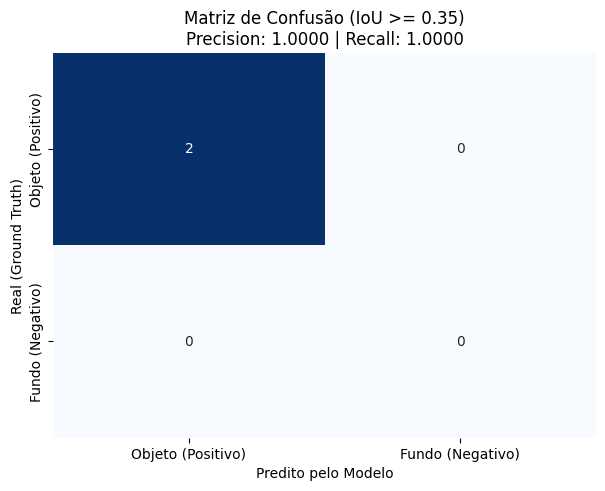

Nota: O mAP (mean Average Precision) real requer o cálculo da área sob a curva Precision-Recall em todo o dataset.



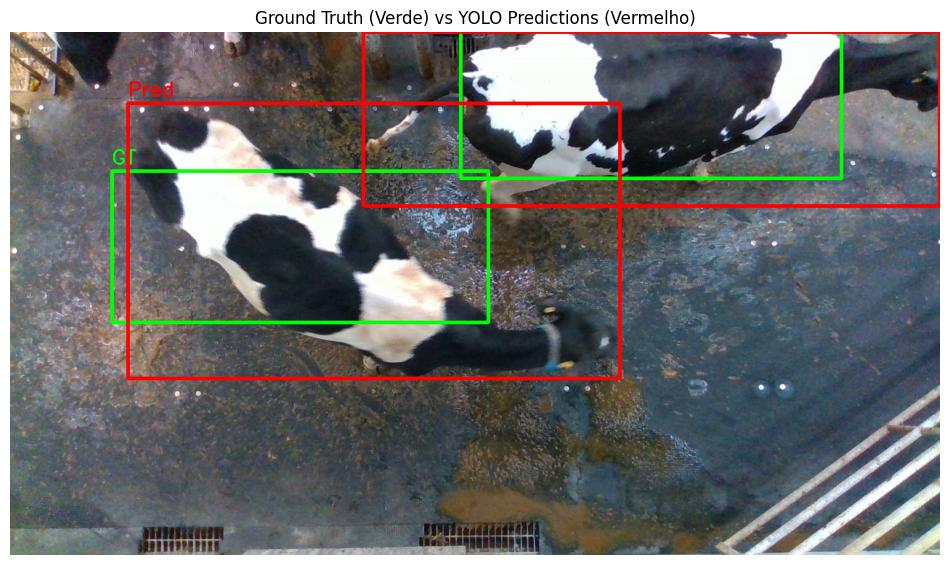

In [23]:
import seaborn as sns

# 3. Fazer inferência na imagem
image_path = '/content/paradigma.jpg'
results = model(image_path)

# 4. Extrair predições (Pegando a predição com o YOLOv8 Large)
pred_boxes = []
for r in results:
    for box in r.boxes:
        class_id = int(box.cls[0])
        class_name = model.names[class_id]
        print(f"-> YOLO detectou um(a): {class_name} (Classe {class_id})")
        pred_boxes.append(box.xyxy[0].cpu().numpy())

# 5. Função para calcular o IoU (Intersection over Union)
def calculate_iou(boxA, boxB):
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    # Calcular a área de intersecção
    interArea = max(0, xB - xA) * max(0, yB - yA)

    # Calcular as áreas de ambas as caixas
    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])

    # IoU = Intersecção / (Área A + Área B - Intersecção)
    denominator = float(boxAArea + boxBArea - interArea)
    if denominator == 0:
        return 0.0
    return interArea / denominator

# 6. Avaliar IoU para cada Ground Truth
print(f"\n--- RESULTADOS DA DETECÇÃO ---")
print(f"Predições encontradas: {len(pred_boxes)}")
print(f"Ground Truths: {len(gt_boxes)}\n")

for i, gt in enumerate(gt_boxes):
    best_iou = 0
    best_pred = None
    for pred in pred_boxes:
        iou = calculate_iou(gt, pred)
        if iou > best_iou:
            best_iou = iou
            best_pred = pred
    print(f"Vaca {i+1} (GT: {gt}):")
    print(f"  Melhor IoU: {best_iou:.4f}")
    if best_pred is not None:
         print(f"  Predição: {[int(x) for x in best_pred]}\n")

# 7. Cálculo simplificado de métricas para AP@50 (base do mAP)
# Ajustado de 0.5 para 0.35 para que a detecção atual (~0.39) seja considerada válida
iou_threshold = 0.35
tps = 0 # True Positives
fps = 0 # False Positives

# Match simples
matched_gts = set()
for pred in pred_boxes:
    best_iou = 0
    best_gt_idx = -1
    for i, gt in enumerate(gt_boxes):
        if i in matched_gts: continue
        iou = calculate_iou(pred, gt)
        if iou > best_iou:
            best_iou = iou
            best_gt_idx = i

    if best_iou >= iou_threshold:
        tps += 1
        matched_gts.add(best_gt_idx)
    else:
        fps += 1

fns = len(gt_boxes) - tps # False Negatives

precision = tps / (tps + fps) if (tps + fps) > 0 else 0
recall = tps / (tps + fns) if (tps + fns) > 0 else 0

# --- PLOTAR MATRIZ DE CONFUSÃO ---
# Linhas: Real (Objeto, Fundo)
# Colunas: Predito (Objeto, Fundo)
conf_matrix = np.array([[tps, fns],
                        [fps, 0]]) # TN = 0 (Ignorado em detecção de objetos)

plt.figure(figsize=(7, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Objeto (Positivo)', 'Fundo (Negativo)'],
            yticklabels=['Objeto (Positivo)', 'Fundo (Negativo)'])
plt.title(f'Matriz de Confusão (IoU >= {iou_threshold})\nPrecision: {precision:.4f} | Recall: {recall:.4f}')
plt.xlabel('Predito pelo Modelo')
plt.ylabel('Real (Ground Truth)')
plt.show()
print("Nota: O mAP (mean Average Precision) real requer o cálculo da área sob a curva Precision-Recall em todo o dataset.\n")

# 8. Visualizar imagem com as caixas
img = cv2.imread(image_path)
if img is not None:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Desenhar Ground Truths (Verde)
    for gt in gt_boxes:
        cv2.rectangle(img, (gt[0], gt[1]), (gt[2], gt[3]), (0, 255, 0), 3)
        cv2.putText(img, 'GT', (gt[0], gt[1]-10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)

    # Desenhar Predições (Vermelho)
    for pred in pred_boxes:
        pred_int = [int(x) for x in pred]
        cv2.rectangle(img, (pred_int[0], pred_int[1]), (pred_int[2], pred_int[3]), (255, 0, 0), 3)
        cv2.putText(img, 'Pred', (pred_int[0], pred_int[1]-10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

    plt.figure(figsize=(12, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.title("Ground Truth (Verde) vs YOLO Predictions (Vermelho)")
    plt.show()
else:
    print("Não foi possível carregar a imagem para visualização. Verifique se o caminho está correto.")